# IEEE 37-bus modified ERCOT sequential DDPG reward matrix

## Purpose

This notebook trains, evaluates, or views sequential DDPG runs under the `band` reward with an added deviation term. The matrix compares three cells: `abs` alpha `0.1`, `sq` alpha `0.001`, and `exp` alpha `1e-05`. The `alpha = 0` control comes from `sq_ercot_ddpg.ipynb` and is only read here. Loads follow measured ERCOT hourly loads from the saved archive splits. Results describe this saved validation split.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]
if not (ROOT / "src/feeder").is_dir():
    raise RuntimeError("Start the kernel in the notebook directory (experiments/<feeder>/).")
sys.path.insert(0, str(ROOT / "src"))

from common.reports import show_reward_matrix, show_reward_matrix_conclusions, show_reward_matrix_training
from common.workflow import run_experiment_matrix

print("Repository root resolved.")

Repository root resolved.


## Parameters

Edit this cell, then restart the kernel and run all cells. `MODE` selects `train`, `evaluate`, or read-only `view` for the three cells; `OVERWRITE` affects only writing modes. The control always runs in `view` mode.

In [2]:
FEEDER = "ieee37mod"  # Named feeder.
DATASET = "ieee37mod-ercot"  # Named dataset.
SEEDS = [0, 1, 2]  # Independent training seeds.
MODE = "view"  # train, evaluate, or read saved results.
OVERWRITE = False  # Applies only to train and evaluate.
TRAINING_DAYS = 7985  # Training only: complete days per run.
BETA = 1e-5  # Reward and benchmark switching-cost weight per tap step.
SPLIT = "validation"  # Evaluation split.
EVALUATION_DAYS = None  # Complete split or a positive day limit.
RATE = 20.0  # Exponent rate of the exp deviation.
CONTROL_RUN_NAME = "band_b1e-05"  # Control run name before _seed<seed>.
CELLS = [  # Deviation kind, alpha, run name before _seed<seed>.
    ("abs", 0.1, "band_b1e-05_abs_a0.1"),
    ("sq", 0.001, "band_b1e-05_sq_a0.001"),
    ("exp", 0.00001, "band_b1e-05_exp_a1e-05"),
]
PLOT_DAY = 280  # Selected evaluated day by zero-based position.

**Units and interfaces.** Each reward adds `alpha` times the mean deviation of `|v - 1|` to the band cost. `BETA` weights executed tap steps. Reported costs and mean absolute deviation are fixed metrics that do not depend on the training reward.

In [3]:
BASE = {
    "protocol": "sequential",
    "algorithm": "ddpg",
    "feeder": FEEDER,
    "dataset": DATASET,
    "seeds": SEEDS,
    "mode": MODE,
    "overwrite": OVERWRITE,
    "training_days": TRAINING_DAYS,
    "reward": "band",
    "beta": BETA,
    "split": SPLIT,
    "evaluation_days": EVALUATION_DAYS,
    "run_name": CONTROL_RUN_NAME,
    "plot_day": PLOT_DAY,
    "show_hourly_details": False,
    "root": ROOT,
}
control, cells = run_experiment_matrix(BASE, CELLS, rate=RATE)

Cell band_b1e-05: reward band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed0/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed1/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_seed2/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 5 methods.
Cell band_b1e-05_abs_a0.1: reward band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed0/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed1/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_abs_a0.1_seed2/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 5 methods.
Cell band_b1e-05_sq_a0.001: reward band {'beta': 1e-05, 'deviation': 'sq', 'alpha': 0.001, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-ercot/seq_ddpg/band_b1e-05_sq_a0.001_seed0/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_sq_a0.001_seed1/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_sq_a0.001_seed2/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 5 methods.
Cell band_b1e-05_exp_a1e-05: reward band {'beta': 1e-05, 'deviation': 'exp', 'alpha': 1e-05, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-ercot/seq_ddpg/band_b1e-05_exp_a1e-05_seed0/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_exp_a1e-05_seed1/, results/ieee37mod-ercot/seq_ddpg/band_b1e-05_exp_a1e-05_seed2/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.


Day and hour alignment passed for 636 days, 15264 hours, and 5 methods.


## Training records

These records cover the three cells and the `alpha = 0` baseline. “Training combined cost per day” uses one physical cost definition across cells. Each curve averages the selected seeds before smoothing.

Cost uses the fixed evaluation metric on training episodes and includes exploration. These curves are not held-out performance or proof of convergence.

Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training days,Update counts
DDPG seed 0,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable
DDPG seed 1,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable
DDPG seed 2,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable


Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training days,Update counts
DDPG seed 0,band,"{'beta': 1e-05, 'deviation': 'sq', 'alpha': 0.001, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable
DDPG seed 1,band,"{'beta': 1e-05, 'deviation': 'sq', 'alpha': 0.001, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable
DDPG seed 2,band,"{'beta': 1e-05, 'deviation': 'sq', 'alpha': 0.001, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable


Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training days,Update counts
DDPG seed 0,band,"{'beta': 1e-05, 'deviation': 'exp', 'alpha': 1e-05, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable
DDPG seed 1,band,"{'beta': 1e-05, 'deviation': 'exp', 'alpha': 1e-05, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable
DDPG seed 2,band,"{'beta': 1e-05, 'deviation': 'exp', 'alpha': 1e-05, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable


Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training days,Update counts
DDPG seed 0,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable
DDPG seed 1,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable
DDPG seed 2,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.0, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",7985,unavailable


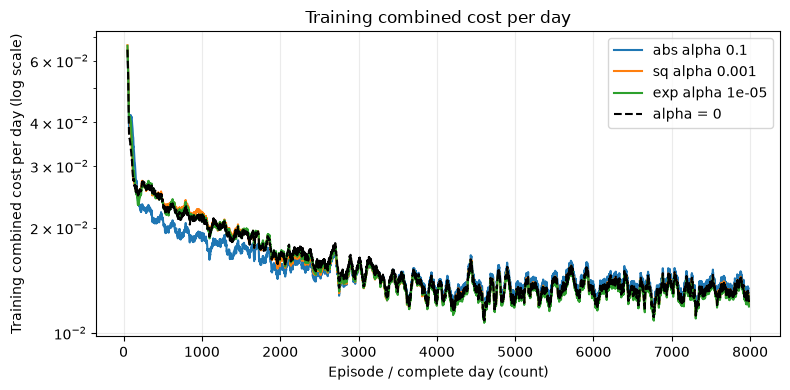

Cost uses the fixed evaluation metric on training episodes and includes exploration. It is not held-out performance or proof of convergence.

In [4]:
show_reward_matrix_training(cells, control);

## Reward matrix

Each cell is a seed mean ± sample standard deviation of per-run metrics. Paired differences match seeds and inputs; spread across three seeds is not a confidence interval.

The selected day follows measured ERCOT hourly loads, normalised by the calendar-year peak.

Cell,Mean daily combined cost
abs alpha 0.1,8.23621e-04 ± 1.86835e-04
sq alpha 0.001,3.71465e-04 ± 3.25818e-05
exp alpha 1e-05,3.55989e-04 ± 5.24598e-05
alpha = 0,2.88068e-04 ± 3.35927e-06


Cell,Mean daily voltage cost
abs alpha 0.1,3.79083e-05 ± 1.74707e-06
sq alpha 0.001,2.47040e-05 ± 2.81807e-06
exp alpha 1e-05,2.93696e-05 ± 8.74216e-06
alpha = 0,3.83200e-05 ± 1.06652e-05


Cell,Mean absolute deviation (p.u.)
abs alpha 0.1,7.3774e-03 ± 2.5825e-04
sq alpha 0.001,2.3412e-02 ± 5.6805e-03
exp alpha 1e-05,2.3885e-02 ± 4.7177e-03
alpha = 0,2.9663e-02 ± 2.9701e-03


Cell,Mean tap steps/day
abs alpha 0.1,78.571 ± 18.509
sq alpha 0.001,34.676 ± 3.365
exp alpha 1e-05,32.662 ± 4.392
alpha = 0,24.975 ± 1.228


Cell,Feasible hours (%)
abs alpha 0.1,37.4 ± 7.2
sq alpha 0.001,53.8 ± 3.7
exp alpha 1e-05,47.8 ± 14.6
alpha = 0,37.1 ± 10.2


Cell,Mean daily voltage cost
abs alpha 0.1,-4.11725e-07 ± 1.20236e-05
sq alpha 0.001,-1.36160e-05 ± 7.91398e-06
exp alpha 1e-05,-8.95038e-06 ± 4.27488e-06


Cell,Mean absolute deviation (p.u.)
abs alpha 0.1,-2.2286e-02 ± 2.7807e-03
sq alpha 0.001,-6.2509e-03 ± 2.7754e-03
exp alpha 1e-05,-5.7784e-03 ± 3.7560e-03


Cell,Mean tap steps/day
abs alpha 0.1,53.596 ± 17.907
sq alpha 0.001,9.701 ± 2.549
exp alpha 1e-05,7.687 ± 5.553


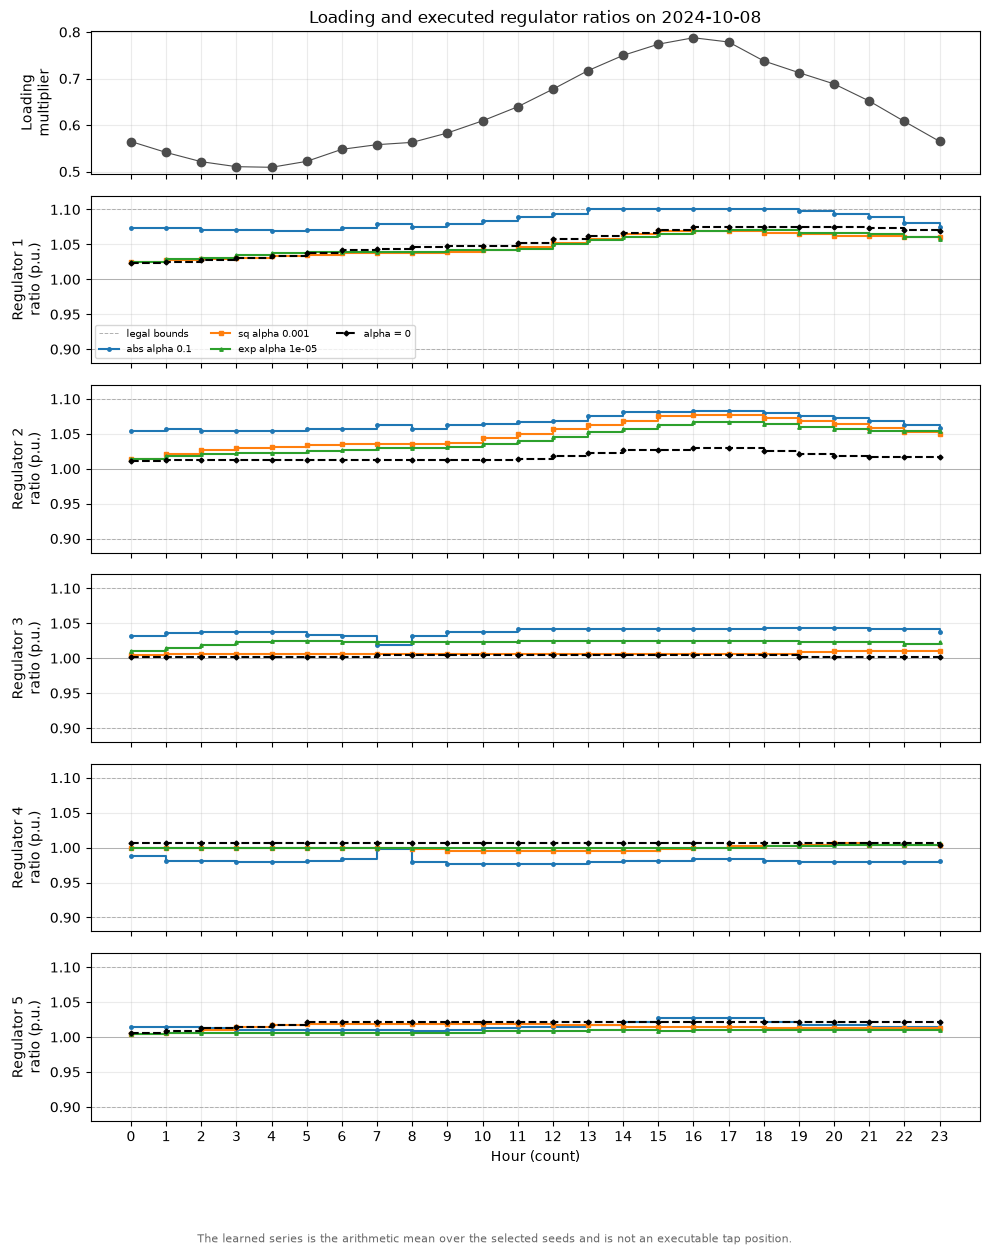

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

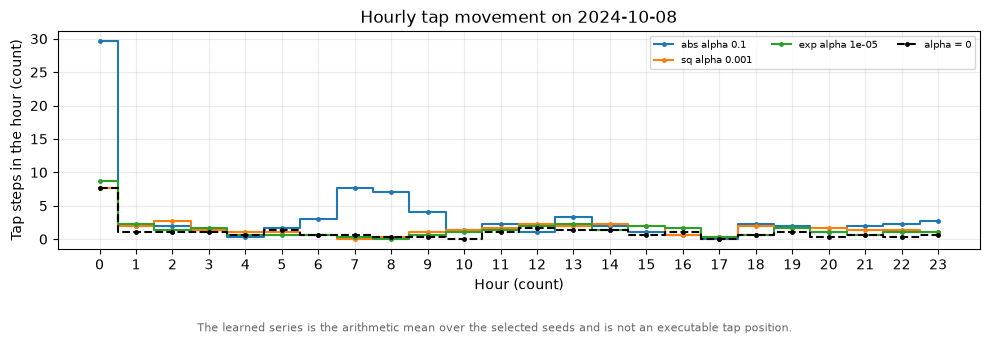

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

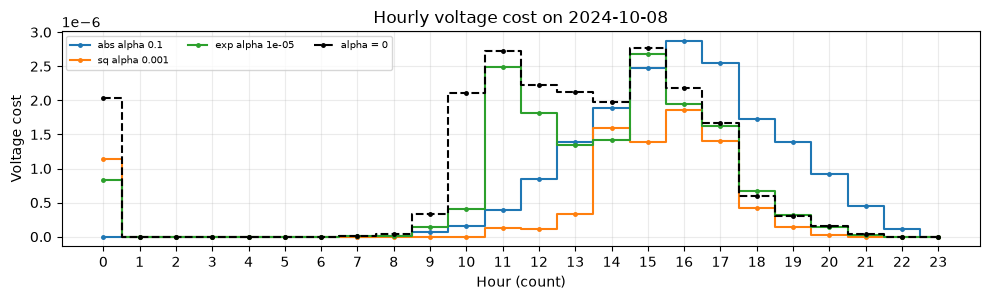

In [5]:
show_reward_matrix(cells, control, include_training=False);

## Final answers

In [6]:
show_reward_matrix_conclusions(cells, control)

Mean daily combined cost: the alpha = 0 control has seed mean 2.88068e-04; the lowest seed mean is 3.55989e-04 for deviation exp, alpha 1e-05.

Mean daily voltage cost: the alpha = 0 control has seed mean 3.83200e-05; the lowest seed mean is 2.47040e-05 for deviation sq, alpha 0.001.

Mean absolute deviation (p.u.): the alpha = 0 control has seed mean 2.9663e-02; the lowest seed mean is 7.3774e-03 for deviation abs, alpha 0.1.

Mean tap steps/day: the alpha = 0 control has seed mean 24.975; the lowest seed mean is 32.662 for deviation exp, alpha 1e-05.

Feasible hours (%): the alpha = 0 control has seed mean 37.1; the highest seed mean is 53.8 for deviation sq, alpha 0.001.

2 of 3 cells have a mean daily voltage cost below the control on all 3 seeds.

These statements describe the saved validation split and these dataset inputs only.